# MLT Assignment #4

Student: Aleksei Chekodanov, group J4133

Is it a cat or a dog? I filled the gaps in the notebook `CNN_and_Transfer_Learning_Pytorch.ipynb`:
- Part 1: CNN with 3 convolutional layers
- Part 2: transfer learning with VGG16 and ResNet50, inference function for my own images

## Convolutional Neural Network



In this notebook you will learn to distinguish dogs from cats!

Data:
https://drive.google.com/drive/folders/1KpT0oBIb3aDaBtjf7Hs4WAUPoFEpbsYr?usp=sharing

Fill all the necessary gaps in cells (all of them are marked with "TO FILL") below and train neural networks for binary classification task.

## Task 1:

1. Build and fit CNN with 3 convolutional layers for binary classification
2. Evaluate accuracy on test data
3. Plot the graphs for Loss(number_of_epochs) and Accuracy(number_of_epochs)

First, let's load all the necessary functions:


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import numpy as np

import os
import time
import matplotlib.pyplot as plt

torch.manual_seed(1)
np.random.seed(1)
print(torch.__version__)

2.13.0


I ran this notebook on my laptop (Apple M2, PyTorch uses the Apple GPU through `mps`), not in Colab. So the cells with `drive.mount` and copying the archive are not needed here.
The archive `Cats_and_Dogs.zip` is unzipped into the folder `Cats_and_Dogs` next to the notebook (the same folders as in the archive: `train`, `val`, `test`).

In [2]:
# result should be 'test  train  val'
print(sorted(os.listdir('Cats_and_Dogs')))

['test', 'train', 'val']


In [3]:
# TO FILL

# Initialize the folders with train, test and validation datasets
# Paths are configured here for the local folder 'Cats_and_Dogs/'

train = 'Cats_and_Dogs/train'
val =   'Cats_and_Dogs/val'
test =  'Cats_and_Dogs/test'

# The shape of the RGB image
img_width, img_height, channels = 150, 150, 3 # you can try different scales

# input shape for PyTorch (channels first)
input_shape = (3, img_height, img_width)  # PyTorch uses (N, C, H, W) format for input data - (batch_size, channels, height, width)

# Set device (GPU if available, otherwise CPU)
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f"Using device: {device}")

# minibatch size. You can try 64 at first, and compare results with 16, 32, 128
batch_size = 64

Using device: mps


## Prepare the data.

You don't have to manually change the shapes of 25000 images and convert them into the necessary format for PyTorch (3, img_width, img_height).

We will use PyTorch's built-in data loading utilities: _transforms_ and _DataLoader_.

It performs scaling, resizes selected images and prepares batches (mini-samples) to train the model.

In [4]:
# Define transforms for data preprocessing
# PyTorch transforms: resize, convert to tensor (scales to [0,1]), and normalize
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),  # Converts to tensor and scales to [0, 1]
    ]),
    'val': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ]),
    'test': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ])
}

# Create datasets using ImageFolder (expects subdirectories for each class)
train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms['test'])

# Create data loaders
# Note: num_workers=2 for Colab (uses multiprocessing for faster data loading)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4,    pin_memory=False,
    persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4,    pin_memory=False,
    persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4,    pin_memory=False,
    persistent_workers=True)

print('classes:', train_dataset.class_to_idx)
print('train:', len(train_dataset), np.bincount(train_dataset.targets))
print('val:  ', len(val_dataset), np.bincount(val_dataset.targets))
print('test: ', len(test_dataset), np.bincount(test_dataset.targets))

classes: {'cats': 0, 'dogs': 1}
train: 20000 [10000 10000]
val:   2490 [1240 1250]
test:  2500 [1250 1250]


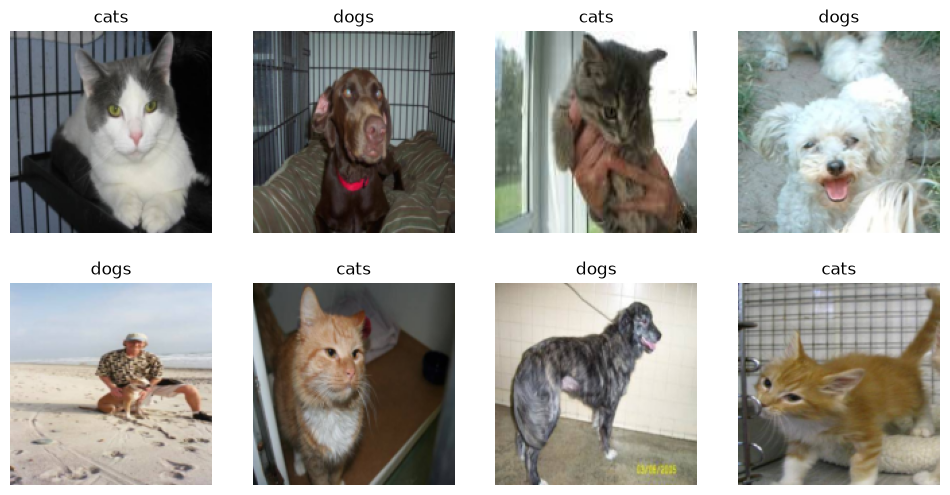

In [5]:
plt.figure(figsize=(12, 6))
for i in range(8):
    idx = np.random.randint(len(train_dataset))
    img, label = train_dataset[idx]
    plt.subplot(2, 4, i + 1)
    plt.imshow(img.permute(1, 2, 0))
    plt.title(train_dataset.classes[label])
    plt.axis('off')
plt.show()

Set the network architecture by sequentially adding layers to it:
1. A convolutional layer with 16 neurons (# output channels), filter size 3x3. Activation function - 'relu'
2. MaxPooling layer with filter size 2x2.
3. A convolutional layer with 32 neurons (# output channels), filter size 3x3. Activation function - 'relu'
4. MaxPooling layer with filter size 2x2.
5. A convolutional layer with 64 neurons (# output channels), filter size 3x3. Activation function - 'relu'
6. MaxPooling layer with filter size 2x2.
7. Flatten operation, which makes a one-dimensional vector of the resulting feature maps.
8. A fully connected layer with 64 neurons. Activation function - 'relu'
9. Dropout(0.5) which excludes neurons with a 50% probability to avoid overfitting.
10. A fully connected layer with 1 neuron. Activation function - 'sigmoid', because binary classification model.

Add to the model all the missing layers, by analogy with the already specified.
PyTorch documentation: https://pytorch.org/docs/stable/nn.html

In [6]:
# TO FILL

# Define CNN model as a PyTorch class
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        # 1: Convolutional layer with 16 output channels, 3x3 kernel
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()

        # 2: MaxPooling layer with 2x2 kernel
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 3: Convolutional layer with 32 output channels
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()

        # 4: Pooling
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 5: Convolutional (64 channels)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()

        # 6: Pooling
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 7: Flatten (handled in forward pass)
        # After 3 pooling layers: 150 -> 75 -> 37 -> 18
        # 8: Dense (Fully Connected) with 64 neurons
        self.fc1 = nn.Linear(64 * 18 * 18, 64)
        self.relu4 = nn.ReLU()

        # 9: Dropout(0.5)
        self.dropout = nn.Dropout(0.5)

        # 10: Dense with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        # Forward pass through the network
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.relu3(x)
        x = self.pool3(x)

        # Flatten: convert (batch, channels, h, w) to (batch, channels*h*w)
        x = x.view(x.size(0), -1)

        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

# Instantiate the model and move to device
model = CNNModel().to(device)
print(model)
print('number of parameters:', sum(p.numel() for p in model.parameters()))

CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=20736, out_features=64, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)
number of parameters: 1350817


In [7]:
# Define loss function and optimizer
# Binary Cross Entropy with Logits (combines Sigmoid and BCE for better numerical stability)
# Note: If using BCEWithLogitsLoss, remove sigmoid from model's last layer
criterion = nn.BCEWithLogitsLoss()
# Alternatively: use nn.BCELoss() if you keep sigmoid in the model

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [8]:
# Training loop for PyTorch

# you can try different number of epochs: 10, 15, 20; check the learning curves, loss and accuracy;
num_epochs = 15

# Lists to store training history
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

start_time = time.time()

# Main training loop
for epoch in range(num_epochs):
    # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)  # Reshape for binary classification

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

print(f'Training time: {(time.time() - start_time) / 60:.1f} min')

Epoch [1/15], Train Loss: 0.6475, Train Acc: 61.39%, Val Loss: 0.5828, Val Acc: 70.92%


Epoch [2/15], Train Loss: 0.5663, Train Acc: 71.27%, Val Loss: 0.5178, Val Acc: 75.02%


Epoch [3/15], Train Loss: 0.5143, Train Acc: 74.93%, Val Loss: 0.4991, Val Acc: 74.62%


Epoch [4/15], Train Loss: 0.4726, Train Acc: 77.50%, Val Loss: 0.4576, Val Acc: 78.92%


Epoch [5/15], Train Loss: 0.4396, Train Acc: 80.40%, Val Loss: 0.4459, Val Acc: 79.32%


Epoch [6/15], Train Loss: 0.4007, Train Acc: 82.22%, Val Loss: 0.4221, Val Acc: 80.56%


... (5 outputs left out)

Epoch [12/15], Train Loss: 0.2135, Train Acc: 90.76%, Val Loss: 0.4226, Val Acc: 83.13%


Epoch [13/15], Train Loss: 0.1985, Train Acc: 91.42%, Val Loss: 0.4517, Val Acc: 82.41%


Epoch [14/15], Train Loss: 0.1712, Train Acc: 92.50%, Val Loss: 0.4522, Val Acc: 83.37%


Epoch [15/15], Train Loss: 0.1636, Train Acc: 92.88%, Val Loss: 0.5377, Val Acc: 83.05%
Training time: 13.4 min


In [9]:
# Evaluate on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")
test_acc_cnn = test_accuracy

Accuracy on test data: 82.68%


Plot the graphs:

- Loss(Number of epochs)

- Accuracy(Number of epochs)

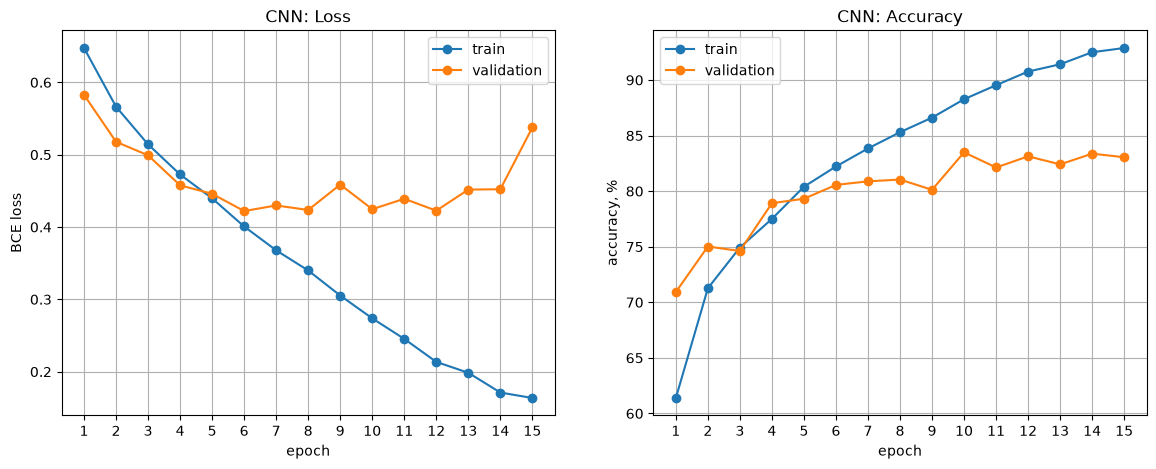

In [10]:
# TO FILL

import matplotlib.pyplot as plt

def plot_history(train_losses, val_losses, train_accuracies, val_accuracies, title):
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(14, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, marker='o', label='train')
    plt.plot(epochs, val_losses, marker='o', label='validation')
    plt.title(title + ': Loss')
    plt.xlabel('epoch')
    plt.ylabel('BCE loss')
    plt.xticks(epochs)
    plt.grid(True)
    plt.legend()

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accuracies, marker='o', label='train')
    plt.plot(epochs, val_accuracies, marker='o', label='validation')
    plt.title(title + ': Accuracy')
    plt.xlabel('epoch')
    plt.ylabel('accuracy, %')
    plt.xticks(epochs)
    plt.grid(True)
    plt.legend()
    plt.show()

plot_history(train_losses, val_losses, train_accuracies, val_accuracies, 'CNN')

Part 1 result: test accuracy 82.68%.

- epochs 1-6: the loss goes down on train and on validation, the network learns
- after epoch 6-8 the network overfits: train loss goes down to 0.16 and train accuracy up to 93%, but validation loss stops going down (0.54 at epoch 15) and validation accuracy stays about 83%
- in the first epochs train accuracy is lower than validation, because train accuracy is averaged during the epoch while the network is still learning, and dropout works only on train
- to make it better we could use augmentation (flips, crops), early stopping on validation loss, batch normalization or more layers

Let's try to improve the quality of recognition, using the method of transfer learning.

We will use weights of deep neural networks already trained on large dataset such as  ImageNet, and provide fine tuning of several additional dense layers on new data relevant to the current classification task. The more new images will differ from those on which the network has been trained, the more layers will need to be “retrained” in order to get good classification accuracy. The intuition here is that the model has already learned how to highlight the necessary features on the images in the large dataset, it only needs to be “tweaked” for a specific task.

## Task 2

1. Build and fit Transfer Learning model using pre-trained VGG16-model weights from torchvision.models.
2. Do the same with **another available pre-trained deep learning model** from torchvision.models https://pytorch.org/vision/stable/models.html.
3. Evaluate accuracy on test data for p.1 and p.2
4. Plot the graphs for Loss(number_of_epochs) and Accuracy(number_of_epochs)
5. Check the performance of your model with the custom image of cat or dog (so the model will tell which class this image belongs to). Develop the function for the inference of the best algorithm.

The pretrained networks were trained on ImageNet: images 224x224, normalized with the ImageNet mean and std. So for Part 2 I made new transforms: resize to 224x224 and `Normalize` with these numbers. For the train images I also added a random horizontal flip (a flipped cat is still a cat).

In [11]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

data_transforms_tl = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ])
}

train_dataset = datasets.ImageFolder(train, transform=data_transforms_tl['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms_tl['test'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms_tl['test'])

batch_size_tl = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size_tl, shuffle=True, num_workers=2, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size_tl, shuffle=False, num_workers=2, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size_tl, shuffle=False, num_workers=2, persistent_workers=True)

In [12]:
# First, download the weights of the VGG16 network trained on the ImageNet dataset:
# PyTorch will automatically download the weights when you first run this

vgg16_net = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)  # Load pre-trained VGG16
# Remove the classifier (fully connected layers) - we take only the "convolution" part
vgg16_net = vgg16_net.features  # Extract only convolutional features

# Freeze the weights - we do NOT want to retrain the VGG16 layers
# Weights VGG16 in the process of learning will remain unchanged!
for param in vgg16_net.parameters():
    param.requires_grad = False

print(vgg16_net)  # pay attention to the architecture

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

We construct our model of "transfer learning" by adding two fully connected layers to VGG16

In [13]:
# Build transfer learning model by adding fully connected layers to VGG16

class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features  # Pre-trained VGG16 features

        # Adaptive pooling to handle feature input sizes
        # That operation shrinks the feature map size to 7x7
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # Flattening (done in forward)
        # Dense fully connected layer with 256 neurons
        self.fc1 = nn.Linear(512 * 7 * 7, 256)  # VGG16 outputs 512 channels
        self.relu = nn.ReLU()

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Dense layer with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)  # Flatten

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

model = VGG16TransferModel(vgg16_net).to(device)
print(model)

VGG16TransferModel(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, paddin

In [14]:
# Define loss and optimizer for transfer learning model
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)  # Lower learning rate 1e-5 for fine-tuning

In [15]:
# TO FILL

# Training loop for transfer learning model

num_epochs_transfer = 5

# Lists to store training history
train_losses_transfer = []
train_accuracies_transfer = []
val_losses_transfer = []
val_accuracies_transfer = []

start_time = time.time()

for epoch in range(num_epochs_transfer):
    # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_losses_transfer.append(running_loss / len(train_loader))
    train_accuracies_transfer.append(100 * correct / total)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_losses_transfer.append(val_running_loss / len(val_loader))
    val_accuracies_transfer.append(100 * val_correct / val_total)

    print(f'Epoch [{epoch+1}/{num_epochs_transfer}], '
          f'Train Loss: {train_losses_transfer[-1]:.4f}, Train Acc: {train_accuracies_transfer[-1]:.2f}%, '
          f'Val Loss: {val_losses_transfer[-1]:.4f}, Val Acc: {val_accuracies_transfer[-1]:.2f}%, '
          f'time: {time.time() - start_time:.0f} s')

print(f'Training time: {(time.time() - start_time) / 60:.1f} min')

Epoch [1/5], Train Loss: 0.0865, Train Acc: 97.31%, Val Loss: 0.0377, Val Acc: 98.88%, time: 473 s


Epoch [2/5], Train Loss: 0.0327, Train Acc: 98.92%, Val Loss: 0.0332, Val Acc: 99.08%, time: 914 s


Epoch [3/5], Train Loss: 0.0253, Train Acc: 99.13%, Val Loss: 0.0314, Val Acc: 99.00%, time: 1322 s


Epoch [4/5], Train Loss: 0.0185, Train Acc: 99.46%, Val Loss: 0.0322, Val Acc: 99.00%, time: 1732 s


Epoch [5/5], Train Loss: 0.0155, Train Acc: 99.57%, Val Loss: 0.0317, Val Acc: 99.12%, time: 2118 s
Training time: 35.3 min


In [16]:
# Evaluate transfer learning model on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")
test_acc_vgg = test_accuracy

Accuracy on test data: 98.80%


Plot the training history for transfer learning:

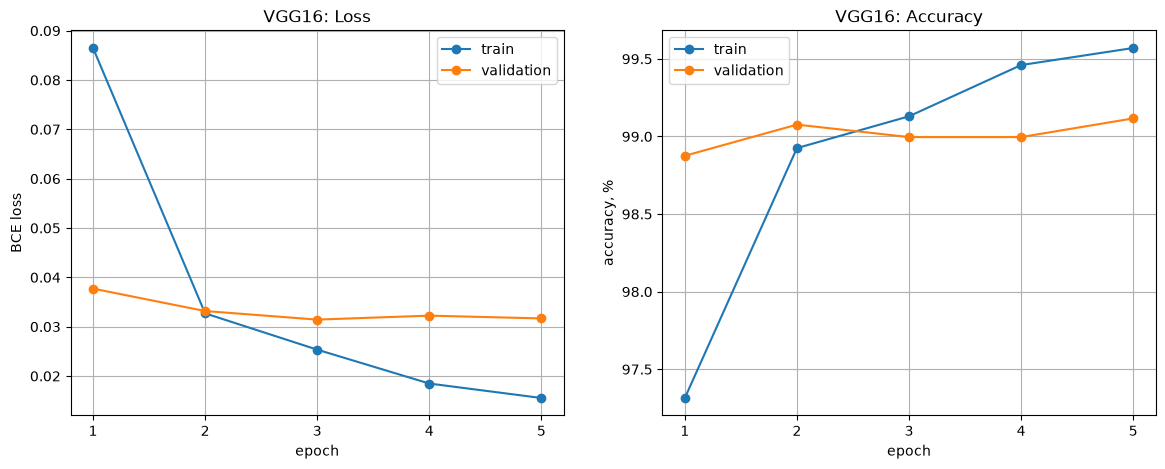

In [17]:
# TO FILL

# Plot learning curves for transfer learning model
plot_history(train_losses_transfer, val_losses_transfer, train_accuracies_transfer, val_accuracies_transfer, 'VGG16')

VGG16 test accuracy is 98.80%, much better than our CNN (82.68%). Already after the first epoch validation accuracy is 98.9%: the pretrained convolutional layers already know good features (fur, ears, faces) and we train only the new fully connected layers. After epoch 3 the validation loss almost does not change, so 5 epochs are enough.

## Another Transfer Learning model (on your choice from https://pytorch.org/vision/stable/models.html.)

I chose ResNet50. It is much deeper than VGG16 (50 layers) because of the skip connections, but it has fewer parameters (25.6M vs 138M) and works faster. I use it the same way: freeze all the pretrained layers and train only the new fully connected layers.

In [18]:
# TO FILL

# Repeat Transfer learning with another pre-trained weights
resnet50_net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

for param in resnet50_net.parameters():
    param.requires_grad = False

resnet50_net.fc = nn.Sequential(
    nn.Linear(2048, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 1)
)

model_resnet = resnet50_net.to(device)
print(model_resnet.fc)
print('trainable parameters:', sum(p.numel() for p in model_resnet.parameters() if p.requires_grad))

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_resnet.fc.parameters(), lr=1e-4)

Sequential(
  (0): Linear(in_features=2048, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=256, out_features=1, bias=True)
)
trainable parameters: 524801


In [19]:
num_epochs_resnet = 5

train_losses_resnet = []
train_accuracies_resnet = []
val_losses_resnet = []
val_accuracies_resnet = []

start_time = time.time()

for epoch in range(num_epochs_resnet):
    model_resnet.eval()
    model_resnet.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        optimizer.zero_grad()
        outputs = model_resnet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_losses_resnet.append(running_loss / len(train_loader))
    train_accuracies_resnet.append(100 * correct / total)

    # Validation phase
    model_resnet.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model_resnet(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_losses_resnet.append(val_running_loss / len(val_loader))
    val_accuracies_resnet.append(100 * val_correct / val_total)

    print(f'Epoch [{epoch+1}/{num_epochs_resnet}], '
          f'Train Loss: {train_losses_resnet[-1]:.4f}, Train Acc: {train_accuracies_resnet[-1]:.2f}%, '
          f'Val Loss: {val_losses_resnet[-1]:.4f}, Val Acc: {val_accuracies_resnet[-1]:.2f}%, '
          f'time: {time.time() - start_time:.0f} s')

print(f'Training time: {(time.time() - start_time) / 60:.1f} min')

Epoch [1/5], Train Loss: 0.0861, Train Acc: 98.72%, Val Loss: 0.0207, Val Acc: 99.36%, time: 219 s


Epoch [2/5], Train Loss: 0.0177, Train Acc: 99.57%, Val Loss: 0.0171, Val Acc: 99.52%, time: 442 s


Epoch [3/5], Train Loss: 0.0139, Train Acc: 99.64%, Val Loss: 0.0166, Val Acc: 99.52%, time: 665 s


Epoch [4/5], Train Loss: 0.0119, Train Acc: 99.65%, Val Loss: 0.0173, Val Acc: 99.52%, time: 925 s


Epoch [5/5], Train Loss: 0.0092, Train Acc: 99.73%, Val Loss: 0.0166, Val Acc: 99.56%, time: 1161 s
Training time: 19.3 min


In [20]:
model_resnet.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model_resnet(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_acc_resnet = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_acc_resnet:.2f}%")

Accuracy on test data: 99.32%


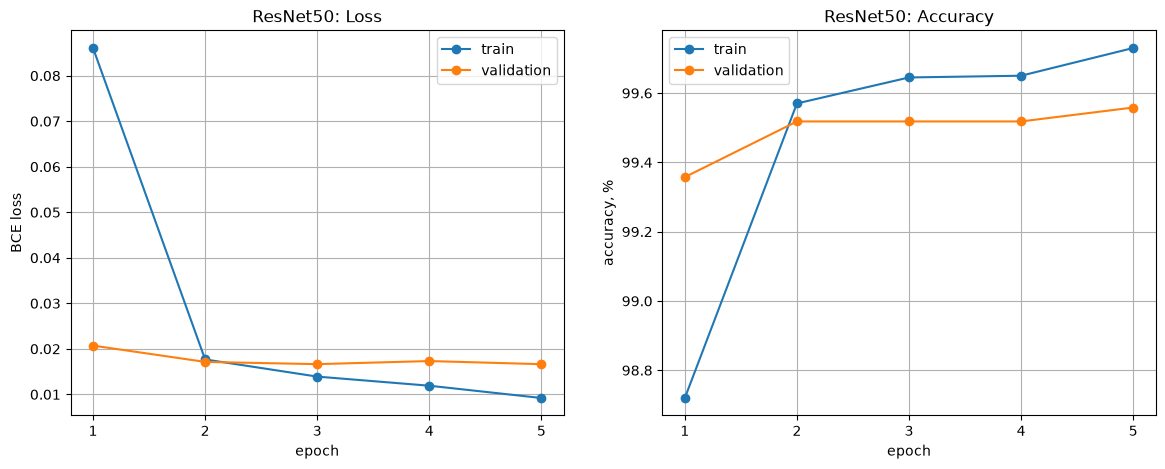

In [21]:
plot_history(train_losses_resnet, val_losses_resnet, train_accuracies_resnet, val_accuracies_resnet, 'ResNet50')

### Comparison of the models

In [22]:
import pandas as pd

results = pd.DataFrame({
    'model': ['CNN (3 conv layers)', 'VGG16 transfer', 'ResNet50 transfer'],
    'epochs': [num_epochs, num_epochs_transfer, num_epochs_resnet],
    'train accuracy, %': [train_accuracies[-1], train_accuracies_transfer[-1], train_accuracies_resnet[-1]],
    'val accuracy, %': [val_accuracies[-1], val_accuracies_transfer[-1], val_accuracies_resnet[-1]],
    'test accuracy, %': [test_acc_cnn, test_acc_vgg, test_acc_resnet],
})
results.round(2)

,model,epochs,"train accuracy, %","val accuracy, %","test accuracy, %"
0,CNN (3 conv layers),15,92.88,83.05,82.68
1,VGG16 transfer,5,99.57,99.12,98.80
2,ResNet50 transfer,5,99.73,99.56,99.32


ResNet50 has the best result: test accuracy 99.32% (VGG16 98.80%, CNN 82.68%). It has fewer parameters than VGG16, but it is deeper and its ImageNet features are better. It is also faster: about 232 s per epoch vs about 420 s for VGG16 on my laptop.

Inference function for custom images with the best model:

In [23]:
# TO FILL

# Function to predict whether a custom image is a cat or a dog
from PIL import Image

def predict_image(image_path, model, device):
    """
    Predicts whether the image is a cat or a dog.

    Args:
        image_path: Path to the image file
        model: Trained PyTorch model
        device: torch device (CPU or CUDA)

    Returns:
        Predicted class and probability
    """
    image = Image.open(image_path).convert('RGB')

    x = data_transforms_tl['test'](image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        prob_dog = torch.sigmoid(model(x)).item()

    if prob_dog > 0.5:
        return 'dog', prob_dog
    else:
        return 'cat', 1 - prob_dog

# Example usage:
# predicted_class, confidence = predict_image('path/to/your/image.jpg', model, device)
# print(f"Predicted: {predicted_class} with confidence {confidence*100:.2f}%")

Best model: ResNet50
my_cat.jpg: Predicted: cat with confidence 99.96%


my_dog.jpg: Predicted: dog with confidence 99.96%


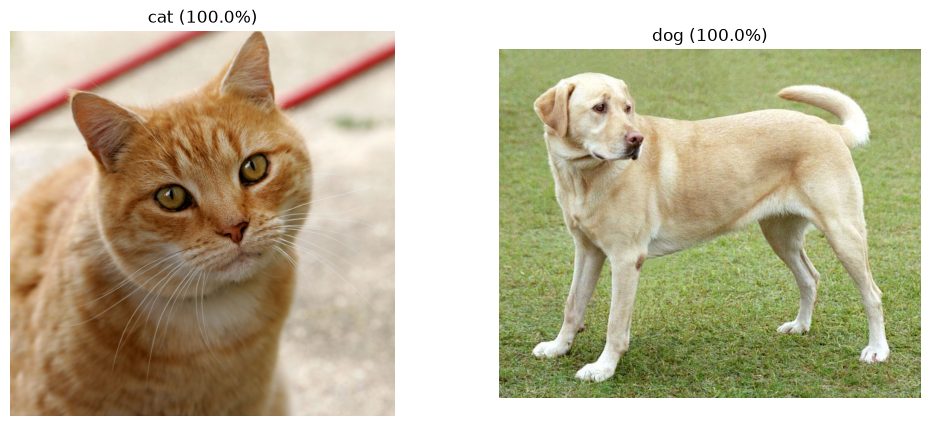

In [24]:
if val_accuracies_resnet[-1] >= val_accuracies_transfer[-1]:
    best_model, best_name = model_resnet, 'ResNet50'
else:
    best_model, best_name = model, 'VGG16'
print('Best model:', best_name)

plt.figure(figsize=(12, 5))
for i, path in enumerate(['my_cat.jpg', 'my_dog.jpg']):
    predicted_class, confidence = predict_image(path, best_model, device)
    print(f"{path}: Predicted: {predicted_class} with confidence {confidence*100:.2f}%")

    plt.subplot(1, 2, i + 1)
    plt.imshow(Image.open(path))
    plt.title(f'{predicted_class} ({confidence*100:.1f}%)')
    plt.axis('off')
plt.show()

### Conclusions

1. The CNN with 3 convolutional layers trained from scratch gives 82.68% on test. After 6-8 epochs it overfits (train 93%, validation 83%).
2. Transfer learning is much better: VGG16 98.80% and ResNet50 99.32% on test. The pretrained layers were trained on 1.2M ImageNet images, so they already extract good features, and we train only the last layers. It also needs only 5 epochs.
3. For the pretrained models the images must be prepared like for ImageNet: 224x224 and normalization with the ImageNet mean and std.
4. In ResNet50 the frozen part is kept in eval mode, otherwise the BatchNorm layers would change their statistics during training.
5. ResNet50 is the best model by validation accuracy, so it is used in predict_image(). On my photos it predicted cat (99.96%) for the cat and dog (99.96%) for the dog.
6. The remaining errors (about 1%) are hard images: small animals, a cat and a dog on one photo, dark photos.